# Дополнительное задание. Прогнозирование временных рядов

## Цель
Освоить базовый пайплайн прогнозирования временного ряда через сведение к задаче регрессии.

## Загрузка и визуализация.

### Импорт библиотек

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.family"] = "DejaVu Sans"

SEED = 42
FREQ = "10min"
H = 144  
TARGET_COL = "T"

### Загрузка и первичный осмотр данных

In [ ]:
candidates = [Path("cleaned_weather.csv"), Path("/mnt/data/cleaned_weather.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)

raw = pd.read_csv(DATA_PATH)

raw["date"] = pd.to_datetime(raw["date"], errors="coerce")
raw[TARGET_COL] = pd.to_numeric(raw[TARGET_COL], errors="coerce")
raw = raw.dropna(subset=["date", TARGET_COL]).sort_values("date").reset_index(drop=True)

print(f"Файл: {DATA_PATH}")
print(f"Размер после удаления строк без даты/цели: {raw.shape[0]:,} строк × {raw.shape[1]} столбцов")
print("Период:", raw["date"].min(), "—", raw["date"].max())
print("\nТипы столбцов:")
display(raw.dtypes.to_frame("dtype"))
print("\nПервые 5 строк:")
display(raw.head())
print("\nКоличество пропусков по столбцам (показаны только столбцы с пропусками):")
missing_by_col = raw.isna().sum()
display(missing_by_col[missing_by_col > 0].to_frame("missing_count"))
if not (missing_by_col > 0).any():
    print("Пропусков в таблице до построения регулярной сетки не обнаружено.")

Файл: cleaned_weather.csv
Размер после удаления строк без даты/цели: 52,696 строк × 21 столбцов
Период: 2020-01-01 00:10:00 — 2021-01-01 00:00:00

Типы столбцов:


,dtype
date,datetime64[us]
p,float64
T,float64
Tpot,float64
Tdew,float64
rh,float64
VPmax,float64
VPact,float64
VPdef,float64
sh,float64



Первые 5 строк:


,date,p,T,Tpot,Tdew,rh,VPmax,VPact,VPdef,sh,...,rho,wv,max. wv,wd,rain,raining,SWDR,PAR,max. PAR,Tlog
0,2020-01-01 00:10:00,1008.89,0.71,273.18,-1.33,86.1,6.43,5.54,0.89,3.42,...,1280.62,1.02,1.60,224.3,0.0,0.0,0.0,0.0,0.0,11.45
1,2020-01-01 00:20:00,1008.76,0.75,273.22,-1.44,85.2,6.45,5.49,0.95,3.39,...,1280.33,0.43,0.84,206.8,0.0,0.0,0.0,0.0,0.0,11.51
2,2020-01-01 00:30:00,1008.66,0.73,273.21,-1.48,85.1,6.44,5.48,0.96,3.39,...,1280.29,0.61,1.48,197.1,0.0,0.0,0.0,0.0,0.0,11.60
3,2020-01-01 00:40:00,1008.64,0.37,272.86,-1.64,86.3,6.27,5.41,0.86,3.35,...,1281.97,1.11,1.48,206.4,0.0,0.0,0.0,0.0,0.0,11.70
4,2020-01-01 00:50:00,1008.61,0.33,272.82,-1.50,87.4,6.26,5.47,0.79,3.38,...,1282.08,0.49,1.40,209.6,0.0,0.0,0.0,0.0,0.0,11.81



Количество пропусков по столбцам (показаны только столбцы с пропусками):


,missing_count


Пропусков в таблице до построения регулярной сетки не обнаружено.


### Обработка пропусков и повторов

In [4]:
# Частота между соседними строками исходного файла.
raw_delta = raw["date"].diff()
nonstandard_intervals = raw_delta.notna() & (raw_delta != pd.Timedelta(FREQ))
duplicate_rows = int(raw["date"].duplicated(keep=False).sum())
duplicate_timestamps = int(raw["date"].duplicated().sum())

# Для целевого ряда повторные наблюдения в один момент усредняются.
y_observed = raw.groupby("date")[TARGET_COL].mean().sort_index()
regular_index = pd.date_range(y_observed.index.min(), y_observed.index.max(), freq=FREQ)
y_regular = y_observed.reindex(regular_index)
n_missing_on_grid = int(y_regular.isna().sum())

# Интерполяция разрешена только между известными временными отметками.
y_regular = y_regular.interpolate(method="time", limit_area="inside")
if y_regular.isna().any():
    raise ValueError("После интерполяции остались пропуски. Проверьте начало и конец ряда.")
y = y_regular.astype(float).rename(TARGET_COL)
y.index.name = "date"

print(f"Строк с временной отметкой, которая повторяется (включая первое вхождение): {duplicate_rows}")
print(f"Лишних повторов временной отметки: {duplicate_timestamps}")
print(f"Интервалов между строками, отличающихся от {FREQ}: {int(nonstandard_intervals.sum())}")
print(f"Пропусков после построения регулярной сетки, заполненных интерполяцией: {n_missing_on_grid}")
print(f"Размер регулярного ряда: {len(y):,}")
print("Проверка частоты:", pd.infer_freq(y.index))
print("Проверка пропусков после очистки:", int(y.isna().sum()))
print("Первые/последние временные отметки:", y.index[0], "/", y.index[-1])

display(y.describe().to_frame("T"))

Строк с временной отметкой, которая повторяется (включая первое вхождение): 2
Лишних повторов временной отметки: 1
Интервалов между строками, отличающихся от 10min: 2
Пропусков после построения регулярной сетки, заполненных интерполяцией: 9
Размер регулярного ряда: 52,704
Проверка частоты: 10min
Проверка пропусков после очистки: 0
Первые/последние временные отметки: 2020-01-01 00:10:00 / 2021-01-01 00:00:00


,T
count,52704.000000
mean,10.819399
std,7.468246
min,-6.440000
25%,4.590000
50%,10.230000
75%,16.190000
max,34.800000


### График ряда

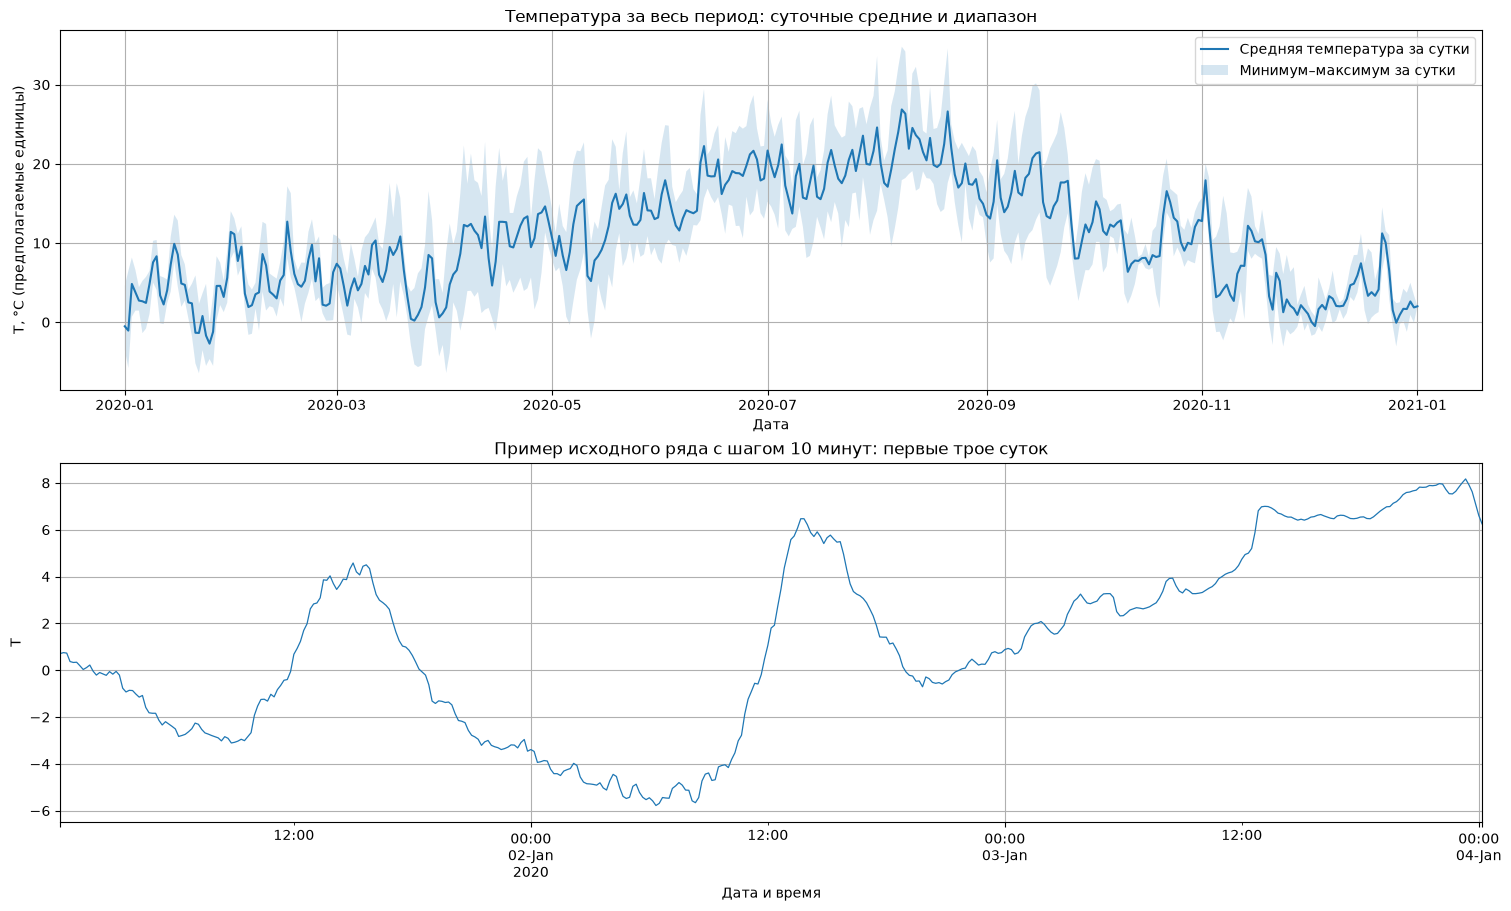

Температура по месяцам — сводная статистика:


,mean_T,min_T,max_T
January,3.46,-6.44,14.02
February,5.76,-1.59,17.16
March,5.39,-5.66,17.57
April,10.39,-6.40,22.79
May,11.89,-2.06,24.11
June,17.36,7.39,29.44
July,18.96,8.12,28.62
August,20.76,9.60,34.80
September,15.41,2.68,30.16
October,10.87,1.74,20.65


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), constrained_layout=True)

daily_mean = y.resample("D").mean()
daily_min = y.resample("D").min()
daily_max = y.resample("D").max()
axes[0].plot(daily_mean.index, daily_mean.values, linewidth=1.5, label="Средняя температура за сутки")
axes[0].fill_between(daily_mean.index, daily_min.values, daily_max.values, alpha=0.18, label="Минимум–максимум за сутки")
axes[0].set_title("Температура за весь период: суточные средние и диапазон")
axes[0].set_xlabel("Дата")
axes[0].set_ylabel("T, °C (предполагаемые единицы)")
axes[0].legend()

start_slice = y.index[0]
end_slice = start_slice + pd.Timedelta(days=3)
y.loc[start_slice:end_slice].plot(ax=axes[1], linewidth=0.9)
axes[1].set_title("Пример исходного ряда с шагом 10 минут: первые трое суток")
axes[1].set_xlabel("Дата и время")
axes[1].set_ylabel("T")
plt.show()

monthly_stats = y.groupby(y.index.month).agg(["mean", "min", "max"])
monthly_stats.index = [pd.Timestamp(2000, m, 1).strftime("%B") for m in monthly_stats.index]
monthly_stats.columns = ["mean_T", "min_T", "max_T"]
print("Температура по месяцам — сводная статистика:")
display(monthly_stats.round(2))

### Вывод

## Признаки

## Разделение и кросс-валидация

## Модель

## Оценка качества

## Декомпозиция

## Вывод